# Лабораторная работа №16: Визуальные токенизаторы и autoregressive image generation

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Обучить compact VQ-VAE.
- Измерить reconstruction и codebook utilization.
- Обучить autoregressive prior и сравнить sampling.

## Теоретическая часть

VQ-VAE кодирует изображение в grid latent vectors, заменяет каждый ближайшим codebook vector и декодирует. Индексы становятся visual tokens для autoregressive prior. Малый codebook ухудшает reconstruction, большой может иметь dead codes.

![VQ-VAE](https://raw.githubusercontent.com/CompVis/taming-transformers/master/assets/teaser.png)


VQ-VAE заменяет пространственные признаки ближайшими векторами кодбука, straight-through переносит градиент через дискретизацию. Conditional autoregressive prior предсказывает очередной visual token по уже известным индексам и метке класса.

Для индекса $k^*=\arg\min_k\|z_e-e_k\|_2^2$ straight-through задаёт $z_q=z_e+\operatorname{sg}(e_{k^*}-z_e)$. Perplexity кодов равна $\exp(-\sum_k p_k\log p_k)$.

### Экспериментальный протокол

MNIST train 20 000/test 2 000; 28×28→7×7 visual tokens. Два токенизатора K=16/64; обученный conditional Transformer; 1000 шагов каждого в полном режиме. Smoke 2 шага — только техническая проверка.

### Материалы

- [VQ-VAE](https://arxiv.org/abs/1711.00937)
- [Taming Transformers](https://github.com/CompVis/taming-transformers)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

In [1]:
from pathlib import Path
import os, json, random, time
import numpy as np
import torch
SEED = 42
FAST_DEV_RUN = False  # True только для короткой проверки связности, не для сдачи.
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
# локально работаю на Apple Silicon, поэтому кроме CUDA проверяю MPS
DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
ARTIFACTS = Path(os.environ.get('CV_ARTIFACTS', 'artifacts'))
ARTIFACTS.mkdir(parents=True, exist_ok=True)
DATA_ROOT = Path(os.environ.get('CV_COURSE_DATA', str(Path.cwd().parents[1] / 'data')))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
def save_json(name, value):
    destination = ARTIFACTS / name
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(json.dumps(value, ensure_ascii=False, indent=2))
print({'device':DEVICE,'fast_dev_run':FAST_DEV_RUN,'artifacts':str(ARTIFACTS)})

{'device': 'mps', 'fast_dev_run': False, 'artifacts': 'artifacts'}


### Архитектура дискретного токенизатора

*Вес: 1 балл.*

**Постановка.** Кодбук должен обучаться на реальных изображениях; random inputs не измеряют качество реконструкции. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите VQ-VAE, ближайший код, straight-through и loss с корректными масштабами.

**Результат.** Проверяемое состояние «Архитектура дискретного токенизатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите VQ-VAE, ближайший код, straight-through и loss с корректными масштабами» и его результат доступен следующему этапу.

In [2]:
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import DataLoader, TensorDataset

mnist_train = torchvision.datasets.MNIST(DATA_ROOT, train=True, download=True)
mnist_test = torchvision.datasets.MNIST(DATA_ROOT, train=False, download=True)
N_TRAIN, N_TEST = 20000, 2000
X_train = mnist_train.data[:N_TRAIN].float().div(255).unsqueeze(1); y_train = mnist_train.targets[:N_TRAIN]
X_test = mnist_test.data[:N_TEST].float().div(255).unsqueeze(1); y_test = mnist_test.targets[:N_TEST]

class VectorQuantizer(nn.Module):
    def __init__(self, K, D, beta=0.25):
        super().__init__()
        self.K, self.D, self.beta = K, D, beta
        self.codebook = nn.Embedding(K, D)
        self.codebook.weight.data.uniform_(-1 / K, 1 / K)
    def forward(self, z_e):                                   # z_e: [B, D, H, W]
        z = z_e.permute(0, 2, 3, 1).reshape(-1, self.D)
        d = (z.pow(2).sum(1, keepdim=True) - 2 * z @ self.codebook.weight.T + self.codebook.weight.pow(2).sum(1)[None])
        idx = d.argmin(1)                                    # ближайший код
        z_q = self.codebook(idx).view(z_e.shape[0], z_e.shape[2], z_e.shape[3], self.D).permute(0, 3, 1, 2)
        codebook_loss = F.mse_loss(z_q, z_e.detach())           # тянет коды к энкодеру
        commit_loss = F.mse_loss(z_e, z_q.detach())             # удерживает энкодер у выбранного кода
        z_q_st = z_e + (z_q - z_e).detach()                     # straight-through: z_q = z_e + sg(e_k − z_e)
        return z_q_st, idx.view(z_e.shape[0], -1), codebook_loss + self.beta * commit_loss

class VQVAE(nn.Module):
    """28×28 → 7×7 токенов; энкодер и декодер свёрточные."""
    def __init__(self, K=64, D=64, ch=64):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(1, ch, 4, 2, 1), nn.ReLU(), nn.Conv2d(ch, 2 * ch, 4, 2, 1), nn.ReLU(),
                                 nn.Conv2d(2 * ch, 2 * ch, 3, 1, 1), nn.ReLU(), nn.Conv2d(2 * ch, D, 1))
        self.vq = VectorQuantizer(K, D)
        self.dec = nn.Sequential(nn.Conv2d(D, 2 * ch, 3, 1, 1), nn.ReLU(), nn.ConvTranspose2d(2 * ch, ch, 4, 2, 1), nn.ReLU(),
                                 nn.ConvTranspose2d(ch, 1, 4, 2, 1))
    def encode(self, x):
        return self.vq(self.enc(x))
    def decode_indices(self, idx):                            # idx: [B, 49]
        z_q = self.vq.codebook(idx).view(idx.shape[0], 7, 7, -1).permute(0, 3, 1, 2)
        return torch.sigmoid(self.dec(z_q))
    def forward(self, x):
        z_q, idx, vq_loss = self.encode(x)
        x_hat = torch.sigmoid(self.dec(z_q))
        return x_hat, idx, vq_loss

def vqvae_loss(x, x_hat, vq_loss):
    recon = F.mse_loss(x_hat, x)         # среднее по пикселям — тот же масштаб, что у слагаемых VQ (среднее по элементам)
    return recon + vq_loss, recon

_m = VQVAE(K=16).to(DEVICE)
_x_hat, _idx, _l = _m(X_train[:4].to(DEVICE))
assert _x_hat.shape == (4, 1, 28, 28) and _idx.shape == (4, 49) and int(_idx.max()) < 16
print("VQ-VAE: вход 28×28 → сетка 7×7 = 49 токенов; параметров", sum(p.numel() for p in _m.parameters()))

VQ-VAE: вход 28×28 → сетка 7×7 = 49 токенов; параметров 495169


### Обучение и диагностика двух кодбуков

*Вес: 1 балл.*

**Постановка.** Кодбук должен обучаться на реальных изображениях; random inputs не измеряют качество реконструкции. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите K=16/64 при равном бюджете; измерьте test MSE, used/dead/perplexity и сохраните checkpoint.

**Результат.** Проверяемое состояние «Обучение и диагностика двух кодбуков» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите K=16/64 при равном бюджете; измерьте test MSE, used/dead/perplexity и сохраните checkpoint» и его результат доступен следующему этапу.

    test_mse used dead perplexity bits_per_image train_seconds
16  0.005784   16    0  11.885328          196.0      7.645894
64  0.004995   35   29  17.089741          294.0       7.74183


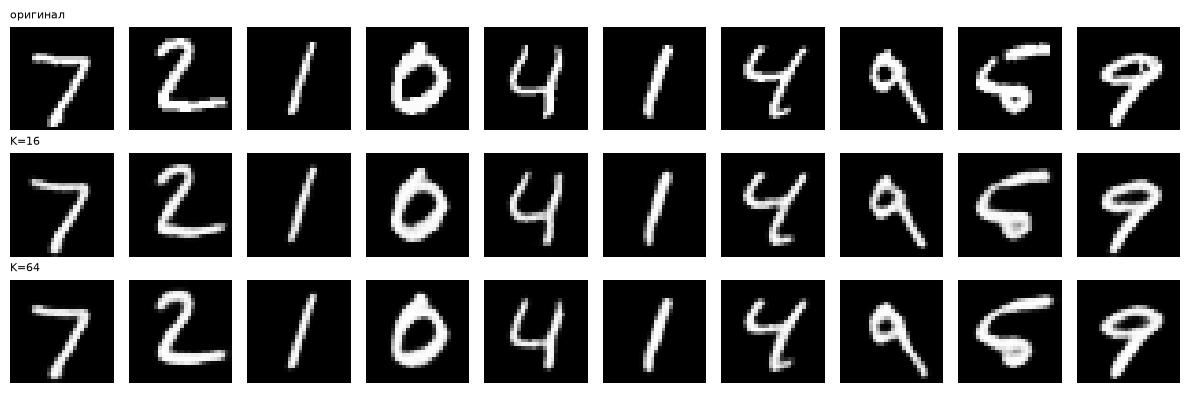

In [3]:
STEPS = 2 if FAST_DEV_RUN else 1000
BATCH = 128

def code_stats(idx, K):
    counts = torch.bincount(idx.flatten(), minlength=K).double()
    p = counts / counts.sum()
    nz = p[p > 0]
    return {"used": int((counts > 0).sum()), "dead": int((counts == 0).sum()), "perplexity": float(torch.exp(-(nz * nz.log()).sum())),
            "top5_codes": torch.argsort(counts, descending=True)[:5].tolist(), "top5_freq": (torch.sort(p, descending=True).values[:5]).tolist()}

def train_vqvae(K, steps=STEPS, seed=SEED):
    path = ARTIFACTS / f"vqvae_K{K}{'_smoke' if FAST_DEV_RUN else ''}.pt"
    torch.manual_seed(seed)
    model = VQVAE(K=K).to(DEVICE)
    if path.exists():
        model.load_state_dict(torch.load(path, map_location=DEVICE)["model"]); return model, torch.load(path, weights_only=False)["history"]
    with torch.no_grad():   # инициализация кодбука выходами энкодера на случайных train-векторах
        z = model.enc(X_train[:512].to(DEVICE)).permute(0, 2, 3, 1).reshape(-1, model.vq.D)
        model.vq.codebook.weight.copy_(z[torch.randperm(len(z), generator=torch.Generator().manual_seed(seed))[:K].to(z.device)])
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    loader = DataLoader(TensorDataset(X_train), batch_size=BATCH, shuffle=True, drop_last=True, generator=torch.Generator().manual_seed(seed))
    hist, step = [], 0
    while step < steps:
        for (x,) in loader:
            x = x.to(DEVICE)
            x_hat, _, vq_l = model(x)
            loss, recon = vqvae_loss(x, x_hat, vq_l)
            opt.zero_grad(); loss.backward(); opt.step()
            hist.append({"loss": loss.item(), "recon": recon.item()}); step += 1
            if step >= steps:
                break
    torch.save({"model": model.state_dict(), "optimizer": opt.state_dict(), "history": hist, "K": K, "steps": steps}, path)
    return model, hist

@torch.no_grad()
def evaluate_vqvae(model, X, K):
    model.eval()
    mse, idxs = [], []
    for i in range(0, len(X), 500):
        x = X[i:i + 500].to(DEVICE)
        x_hat, idx, _ = model(x)
        mse.append(F.mse_loss(x_hat, x, reduction="none").mean((1, 2, 3)).cpu()); idxs.append(idx.cpu())
    mse, idxs = torch.cat(mse), torch.cat(idxs)
    return {"test_mse": float(mse.mean()), **code_stats(idxs, K)}, mse, idxs

tokenizers, tok_report = {}, {}
for K in (16, 64):
    t0 = time.time()
    m, h = train_vqvae(K)
    rep, mse_per_img, _ = evaluate_vqvae(m, X_test, K)
    _, _, train_idx_K = evaluate_vqvae(m, X_train[:5000], K)
    rep.update(train_seconds=time.time() - t0, final_train_recon=float(np.mean([r["recon"] for r in h[-50:]])), steps=len(h),
               dead_on_train5000=code_stats(train_idx_K, K)["dead"], tokens_per_image=49, bits_per_image=49 * float(np.log2(K)))
    tokenizers[K], tok_report[K] = m, rep
save_json("tokenizers.json", tok_report)
import pandas as pd
print(pd.DataFrame(tok_report).T[["test_mse", "used", "dead", "perplexity", "bits_per_image", "train_seconds"]].to_string())

import matplotlib.pyplot as plt
fig, axes = plt.subplots(3, 10, figsize=(12, 4))
with torch.no_grad():
    rec16 = tokenizers[16](X_test[:10].to(DEVICE))[0].cpu(); rec64 = tokenizers[64](X_test[:10].to(DEVICE))[0].cpu()
for c in range(10):
    for r, img in enumerate((X_test[c], rec16[c], rec64[c])):
        axes[r, c].imshow(img[0], cmap="gray", vmin=0, vmax=1); axes[r, c].axis("off")
for r, name in enumerate(("оригинал", "K=16", "K=64")):
    axes[r, 0].set_title(name, fontsize=8, loc="left")
fig.tight_layout(); fig.savefig(ARTIFACTS / "reconstructions.png", dpi=110); plt.show()

### Индексы обученного токенизатора

*Вес: 1 балл.*

**Постановка.** Prior обучается исключительно на индексах обученного токенизатора, без доступа к будущим позициям. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Закодируйте train/test только обученной VQ-VAE K=64.

**Результат.** Проверяемое состояние «Индексы обученного токенизатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Закодируйте train/test только обученной VQ-VAE K=64» и его результат доступен следующему этапу.

In [4]:
vq64 = tokenizers[64].eval()
with torch.no_grad():
    tok_train = torch.cat([vq64.encode(X_train[i:i + 1000].to(DEVICE))[1].cpu() for i in range(0, N_TRAIN, 1000)])
    tok_test = torch.cat([vq64.encode(X_test[i:i + 1000].to(DEVICE))[1].cpu() for i in range(0, N_TEST, 1000)])
assert tok_train.shape == (N_TRAIN, 49) and tok_test.shape == (N_TEST, 49) and int(tok_train.max()) < 64
print("токены train", tuple(tok_train.shape), "test", tuple(tok_test.shape), "| пример:", tok_train[0, :12].tolist())

токены train (20000, 49) test (2000, 49) | пример: [9, 9, 53, 11, 11, 9, 11, 53, 13, 60, 55, 55]


### Причинная маска prior

*Вес: 1 балл.*

**Постановка.** Prior обучается исключительно на индексах обученного токенизатора, без доступа к будущим позициям. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Создайте Transformer с BOS и маской, исключающей просмотр будущих токенов.

**Результат.** Проверяемое состояние «Причинная маска prior» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Создайте Transformer с BOS и маской, исключающей просмотр будущих токенов» и его результат доступен следующему этапу.

In [5]:
class ARPrior(nn.Module):
    """Decoder-only Transformer: [BOS_класса, t_1..t_49]; маска запрещает смотреть на будущие позиции."""
    def __init__(self, K, n_classes=10, d=256, layers=4, heads=4, seq=49):
        super().__init__()
        self.K = K
        self.tok = nn.Embedding(K + n_classes, d)          # индексы K..K+9 — BOS-токены классов
        self.pos = nn.Parameter(torch.zeros(1, seq + 1, d)); nn.init.normal_(self.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, dropout=0.1, batch_first=True, norm_first=True)
        self.blocks = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.norm, self.head = nn.LayerNorm(d), nn.Linear(d, K)
        self.register_buffer("mask", torch.triu(torch.full((seq + 1, seq + 1), float("-inf")), 1))
    def forward(self, seq):                                # seq: [B, L] (BOS + префикс)
        L = seq.shape[1]
        h = self.tok(seq) + self.pos[:, :L]
        h = self.blocks(h, mask=self.mask[:L, :L], is_causal=True)
        return self.head(self.norm(h))                      # логиты следующего токена в каждой позиции

def with_bos(tokens, y, K):
    return torch.cat([(K + y)[:, None], tokens], 1)

prior = ARPrior(64).to(DEVICE)
# проверка причинности: изменение будущего токена не меняет логиты предыдущих позиций
prior.eval()
with torch.no_grad():
    s1 = with_bos(tok_train[:2], y_train[:2], 64).to(DEVICE); s2 = s1.clone(); s2[:, 30] = (s2[:, 30] + 1) % 64
    diff = (prior(s1) - prior(s2)).abs().amax(-1)[0]
assert diff[:30].max() < 1e-4 and diff[30:].max() > 0
print("маска причинная: логиты позиций < 30 не зависят от токена 30; параметров", sum(p.numel() for p in prior.parameters()))

маска причинная: логиты позиций < 30 не зависят от токена 30; параметров 3207744


### Обучение autoregressive prior

*Вес: 1 балл.*

**Постановка.** Prior обучается исключительно на индексах обученного токенизатора, без доступа к будущим позициям. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Оптимизируйте CE сдвинутой последовательности с checkpoint.

**Результат.** Проверяемое состояние «Обучение autoregressive prior» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Оптимизируйте CE сдвинутой последовательности с checkpoint» и его результат доступен следующему этапу.

In [6]:
PRIOR_STEPS = 2 if FAST_DEV_RUN else 1000

def train_prior(prior, tok, y, K, name, steps=PRIOR_STEPS, seed=SEED):
    path = ARTIFACTS / f"{name}{'_smoke' if FAST_DEV_RUN else ''}.pt"
    opt = torch.optim.AdamW(prior.parameters(), lr=3e-4, weight_decay=0.01)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-4, total_steps=steps, pct_start=0.1)
    state = {"step": 0, "loss": []}
    if path.exists():
        ck = torch.load(path, map_location=DEVICE, weights_only=False)
        prior.load_state_dict(ck["model"]); opt.load_state_dict(ck["optimizer"]); sched.load_state_dict(ck["scheduler"]); state = ck["state"]
    g = torch.Generator().manual_seed(seed + state["step"])
    prior.train()
    t0 = time.time()
    while state["step"] < steps:
        b = torch.randint(0, len(tok), (BATCH,), generator=g)
        seq = with_bos(tok[b], y[b], K).to(DEVICE)
        logits = prior(seq[:, :-1])                                  # предсказываем t_1..t_49 по BOS и префиксу
        loss = F.cross_entropy(logits.reshape(-1, K), seq[:, 1:].reshape(-1))
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(prior.parameters(), 1.0); opt.step(); sched.step()
        state["step"] += 1; state["loss"].append(loss.item())
        if state["step"] % 250 == 0 or state["step"] == steps:
            torch.save({"model": prior.state_dict(), "optimizer": opt.state_dict(), "scheduler": sched.state_dict(), "state": state, "K": K}, path)
    state["seconds"] = time.time() - t0
    return state

torch.manual_seed(SEED)
prior = ARPrior(64).to(DEVICE)
prior_state = train_prior(prior, tok_train, y_train, 64, "prior_K64")
print(f"prior K=64: {prior_state['step']} шагов, CE {np.mean(prior_state['loss'][:20]):.3f} → {np.mean(prior_state['loss'][-50:]):.3f}")

prior K=64: 1000 шагов, CE 3.900 → 1.535


### Cross-entropy на test токенах

*Вес: 1 балл.*

**Постановка.** Prior обучается исключительно на индексах обученного токенизатора, без доступа к будущим позициям. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Оцените CE независимых test токенов без обновления весов.

**Результат.** Проверяемое состояние «Cross-entropy на test токенах» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Оцените CE независимых test токенов без обновления весов» и его результат доступен следующему этапу.

In [7]:
@torch.no_grad()
def token_ce(prior, tok, y, K):
    prior.eval()
    total, n = 0.0, 0
    for i in range(0, len(tok), 500):
        seq = with_bos(tok[i:i + 500], y[i:i + 500], K).to(DEVICE)
        logits = prior(seq[:, :-1])
        total += F.cross_entropy(logits.reshape(-1, K), seq[:, 1:].reshape(-1), reduction="sum").item(); n += seq[:, 1:].numel()
    return total / n

ce_test = token_ce(prior, tok_test, y_test, 64)
ce_train = token_ce(prior, tok_train[:2000], y_train[:2000], 64)
prior_report = {"K": 64, "test_ce_nats_per_token": ce_test, "train2000_ce_nats_per_token": ce_train,
                "test_bits_per_image": ce_test * 49 / np.log(2), "uniform_baseline_nats": float(np.log(64)), "steps": prior_state["step"]}
save_json("prior_ce.json", prior_report)
print(json.dumps(prior_report, indent=1))

{
 "K": 64,
 "test_ce_nats_per_token": 1.498151028380102,
 "train2000_ce_nats_per_token": 1.4468019770408163,
 "test_bits_per_image": 105.90737789818702,
 "uniform_baseline_nats": 4.1588830833596715,
 "steps": 1000
}


### Архитектура проверяющего классификатора

*Вес: 1 балл.*

**Постановка.** Сравниваются декодированные изображения, а не распределения случайных токенов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите отдельную сеть для class agreement.

**Результат.** Проверяемое состояние «Архитектура проверяющего классификатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите отдельную сеть для class agreement» и его результат доступен следующему этапу.

In [8]:
class DigitClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.f = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                               nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(),
                               nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10))
    def forward(self, x):            # x в [0, 1]
        return self.f(x)
clf = DigitClassifier().to(DEVICE)
print("проверяющий классификатор не связан с VQ-VAE и prior:", sum(p.numel() for p in clf.parameters()), "параметров")

проверяющий классификатор не связан с VQ-VAE и prior: 421642 параметров


### Обучение и реальный test классификатора

*Вес: 1 балл.*

**Постановка.** Сравниваются декодированные изображения, а не распределения случайных токенов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите на train и проверьте точность на независимом real test.

**Результат.** Проверяемое состояние «Обучение и реальный test классификатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите на train и проверьте точность на независимом real test» и его результат доступен следующему этапу.

In [9]:
torch.manual_seed(SEED)
copt = torch.optim.Adam(clf.parameters(), lr=1e-3)
for epoch in range(1 if FAST_DEV_RUN else 3):
    clf.train()
    for x, y in DataLoader(TensorDataset(X_train, y_train), batch_size=128, shuffle=True, generator=torch.Generator().manual_seed(SEED + epoch)):
        loss = F.cross_entropy(clf(x.to(DEVICE)), y.to(DEVICE))
        copt.zero_grad(); loss.backward(); copt.step()
clf.eval()
with torch.no_grad():
    clf_acc = float((torch.cat([clf(X_test[i:i + 500].to(DEVICE)).argmax(1).cpu() for i in range(0, N_TEST, 500)]) == y_test).float().mean())
    rec_acc = float((clf(tokenizers[64](X_test.to(DEVICE))[0]).argmax(1).cpu() == y_test).float().mean())
save_json("classifier.json", {"test_accuracy_real": clf_acc, "test_accuracy_on_K64_reconstructions": rec_acc, "n_test": N_TEST})
print(f"accuracy классификатора: реальный test {clf_acc:.4f}, реконструкции K=64 {rec_acc:.4f}")

accuracy классификатора: реальный test 0.9715, реконструкции K=64 0.9655


### Фильтрация и семплирование токенов

*Вес: 1 балл.*

**Постановка.** Сравниваются декодированные изображения, а не распределения случайных токенов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Реализуйте temperature, top-k и top-p, генерируя индексы авторегрессионно.

**Результат.** Проверяемое состояние «Фильтрация и семплирование токенов» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Реализуйте temperature, top-k и top-p, генерируя индексы авторегрессионно» и его результат доступен следующему этапу.

In [10]:
def filter_logits(logits, temperature=1.0, top_k=None, top_p=None):
    logits = logits / temperature
    if top_k is not None:
        kth = torch.topk(logits, top_k, dim=-1).values[:, -1:]
        logits = logits.masked_fill(logits < kth, float("-inf"))
    if top_p is not None:
        sorted_logits, order = torch.sort(logits, descending=True, dim=-1)
        cum = torch.softmax(sorted_logits, -1).cumsum(-1)
        remove = cum - torch.softmax(sorted_logits, -1) > top_p        # оставляем минимальное ядро с массой ≥ top_p
        sorted_logits = sorted_logits.masked_fill(remove, float("-inf"))
        logits = torch.full_like(logits, float("-inf")).scatter(-1, order, sorted_logits)
    return logits

@torch.no_grad()
def generate(prior, y, K, seed, **kw):
    prior.eval()
    g = torch.Generator(device="cpu").manual_seed(seed)
    seq = (K + y)[:, None].to(DEVICE)
    for _ in range(49):                                   # токены строго по одному, слева направо
        logits = prior(seq)[:, -1]
        probs = torch.softmax(filter_logits(logits, **kw), -1).cpu()
        nxt = torch.multinomial(probs, 1, generator=g).to(DEVICE)
        seq = torch.cat([seq, nxt], 1)
    return seq[:, 1:].cpu()

_l = torch.tensor([[2.0, 1.0, 0.5, -1.0]])
assert torch.isinf(filter_logits(_l, top_k=2)[0, 2:]).all() and torch.isfinite(filter_logits(_l, top_k=2)[0, :2]).all()
assert torch.isfinite(filter_logits(_l, top_p=0.5)[0, 0]) and torch.isinf(filter_logits(_l, top_p=0.5)[0, 1:]).all()
print("фильтры temperature / top-k / top-p проверены на ручном примере")

фильтры temperature / top-k / top-p проверены на ручном примере


### Декодированная генерация и проверка

*Вес: 1 балл.*

**Постановка.** Сравниваются декодированные изображения, а не распределения случайных токенов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сравните четыре схемы на реальных декодированных изображениях; сохраните измерения.

**Результат.** Проверяемое состояние «Декодированная генерация и проверка» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сравните четыре схемы на реальных декодированных изображениях; сохраните измерения» и его результат доступен следующему этапу.

           class_agreement  mean_confidence  intra_class_l2_diversity  unique_sequences  max_token_share_mean  seconds
T=1.0                0.660           0.8449                    8.7422               1.0                0.2608   1.0532
T=0.7                0.738           0.8814                    8.2479               1.0                0.2810   0.7213
top-k=5              0.778           0.9025                    8.3157               1.0                0.2660   0.7252
top-p=0.9            0.706           0.8719                    8.2744               1.0                0.2753   0.7359
эталон — декодированные токены реального test: {'class_agreement': 0.978, 'mean_confidence': 0.9704, 'intra_class_l2_diversity': 8.3499, 'unique_sequences': 1.0, 'max_token_share_mean': 0.264}


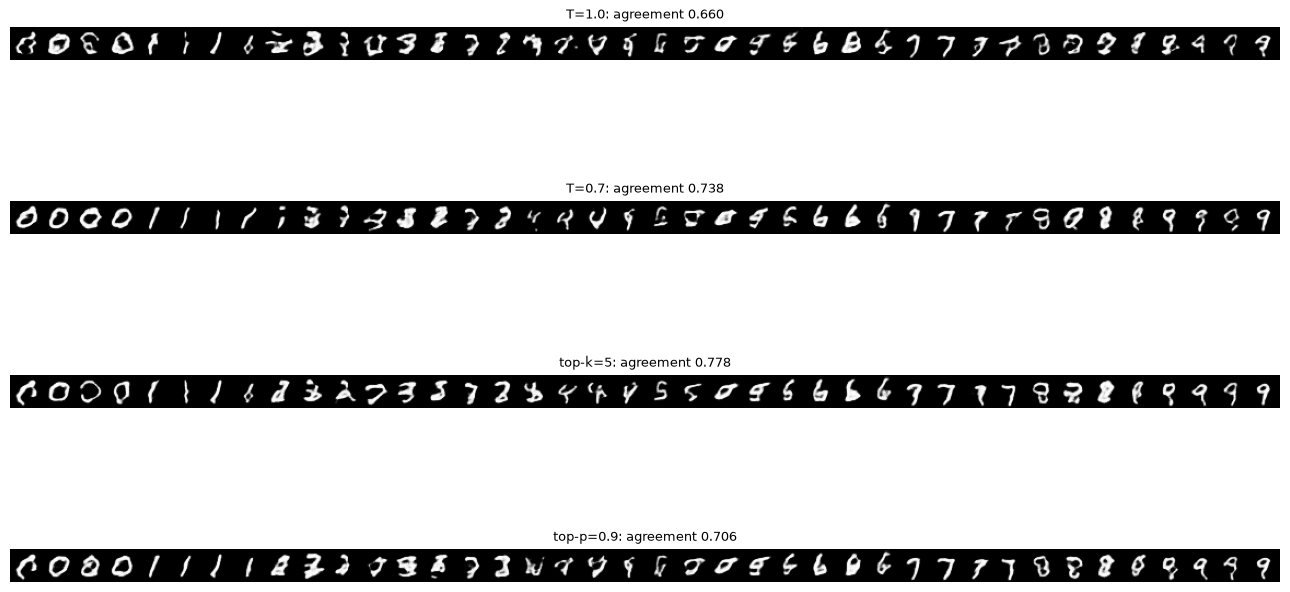

In [11]:
PER_CLASS = 5 if FAST_DEV_RUN else 50
y_gen = torch.arange(10).repeat_interleave(PER_CLASS)
SCHEMES = {"T=1.0": dict(temperature=1.0), "T=0.7": dict(temperature=0.7), "top-k=5": dict(top_k=5), "top-p=0.9": dict(top_p=0.9)}

@torch.no_grad()
def judge(tokens, y, decoder):
    imgs = torch.cat([decoder.decode_indices(tokens[i:i + 250].to(DEVICE)).cpu() for i in range(0, len(tokens), 250)])
    logits = clf(imgs.to(DEVICE)).cpu()
    pred, conf = logits.argmax(1), logits.softmax(1).max(1).values
    div = []
    for c in range(10):
        f = imgs[y == c].flatten(1); d = torch.cdist(f, f)
        div.append(float(d[~torch.eye(len(f), dtype=bool)].mean()))
    rep = torch.tensor([torch.bincount(t, minlength=decoder.vq.K).max().item() / 49 for t in tokens])
    return {"class_agreement": float((pred == y).float().mean()), "mean_confidence": float(conf.mean()),
            "intra_class_l2_diversity": float(np.mean(div)), "unique_sequences": len({tuple(t.tolist()) for t in tokens}) / len(tokens),
            "max_token_share_mean": float(rep.mean())}, imgs, pred, conf

gen_results, gen_imgs = {}, {}
for name, kw in SCHEMES.items():
    t0 = time.time()
    toks = generate(prior, y_gen, 64, seed=SEED + 5, **kw)
    res, imgs, pred, conf = judge(toks, y_gen, vq64)
    res["seconds"] = time.time() - t0
    gen_results[name], gen_imgs[name] = res, (imgs, pred, conf, toks)
real_res = judge(tok_test[:len(y_gen)], y_test[:len(y_gen)], vq64)[0]
save_json("generation.json", {"per_class": PER_CLASS, "schemes": gen_results, "test_tokens_decoded_reference": real_res})
print(pd.DataFrame(gen_results).T.round(4).to_string())
print("эталон — декодированные токены реального test:", {k: round(v, 4) for k, v in real_res.items()})
fig, axes = plt.subplots(len(SCHEMES), 1, figsize=(13, 2 * len(SCHEMES)))
for ax, name in zip(axes, SCHEMES):
    imgs = gen_imgs[name][0]
    grid = torchvision.utils.make_grid(imgs.view(10, PER_CLASS, 1, 28, 28)[:, :4].reshape(-1, 1, 28, 28), nrow=40, padding=1)
    ax.imshow(grid.permute(1, 2, 0)); ax.axis("off"); ax.set_title(f"{name}: agreement {gen_results[name]['class_agreement']:.3f}", fontsize=9)
fig.tight_layout(); fig.savefig(ARTIFACTS / "samples_by_scheme.png", dpi=110); plt.show()

### Типичные ошибки
Худшие реконструкции токенизатора, сгенерированные последовательности с повторяющимися токенами и примеры, где классификатор не узнаёт заданный класс (нарушение глобальной структуры).

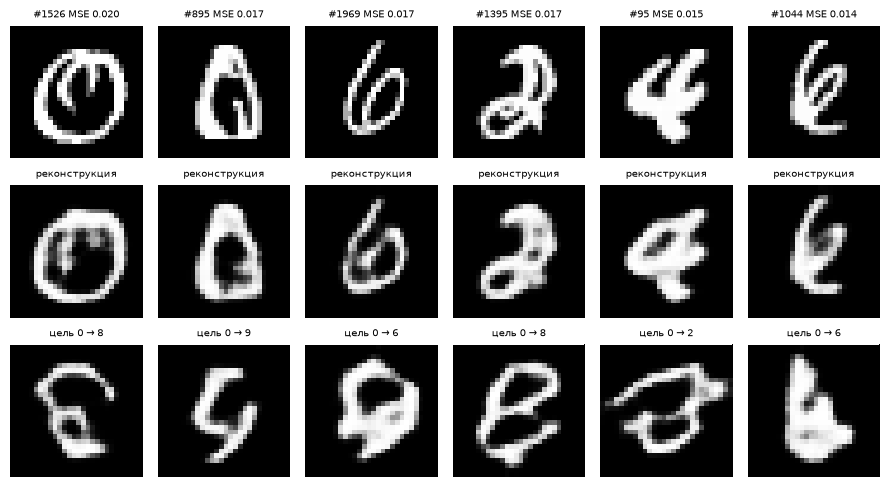

{
 "worst_reconstructions": [
  {
   "test_index": 1526,
   "label": 0,
   "mse": 0.019945379346609116
  },
  {
   "test_index": 895,
   "label": 0,
   "mse": 0.01700388826429844
  },
  {
   "test_index": 1969,
   "label": 6,
   "mse": 0.016979781910777092
  },
  {
   "test_index": 1395,
   "label": 2,
   "mse": 0.01667316071689129
  },
  {
   "test_index": 95,
   "label": 4,
   "mse": 0.014679685235023499
  },
  {
   "test_index": 1044,
   "label": 6,
   "mse": 0.014353209175169468
  }
 ],
 "T=1.0_wrong_class": 170,
 "most_repetitive": [
  {
   "target": 1,
   "max_token_share": 0.5102040767669678,
   "classified_as": 1
  },
  {
   "target": 1,
   "max_token_share": 0.4897959232330322,
   "classified_as": 1
  },
  {
   "target": 1,
   "max_token_share": 0.4897959232330322,
   "classified_as": 1
  },
  {
   "target": 1,
   "max_token_share": 0.4693877696990967,
   "classified_as": 1
  },
  {
   "target": 1,
   "max_token_share": 0.4693877696990967,
   "classified_as": 1
  }
 ]
}


In [12]:
_, mse64, _ = evaluate_vqvae(vq64, X_test, 64)
worst_rec = torch.argsort(mse64, descending=True)[:6]
imgs, pred, conf, toks = gen_imgs["T=1.0"]
rep = torch.tensor([torch.bincount(t, minlength=64).max().item() / 49 for t in toks])
wrong = torch.where(pred != y_gen)[0]
error_report = {"worst_reconstructions": [{"test_index": int(i), "label": int(y_test[i]), "mse": float(mse64[i])} for i in worst_rec],
                "T=1.0_wrong_class": int(len(wrong)), "T=1.0_wrong_examples": [{"target": int(y_gen[i]), "classified_as": int(pred[i]), "confidence": float(conf[i])} for i in wrong[:10]],
                "most_repetitive": [{"target": int(y_gen[i]), "max_token_share": float(rep[i]), "classified_as": int(pred[i])} for i in torch.argsort(rep, descending=True)[:5]]}
save_json("error_cases.json", error_report)
fig, axes = plt.subplots(3, 6, figsize=(9, 5))
with torch.no_grad():
    rec = vq64(X_test[worst_rec].to(DEVICE))[0].cpu()
for k in range(6):
    axes[0, k].imshow(X_test[worst_rec[k], 0], cmap="gray"); axes[0, k].set_title(f"#{int(worst_rec[k])} MSE {mse64[worst_rec[k]]:.3f}", fontsize=7)
    axes[1, k].imshow(rec[k, 0], cmap="gray"); axes[1, k].set_title("реконструкция", fontsize=7)
    if k < len(wrong):
        i = wrong[k]; axes[2, k].imshow(imgs[i, 0], cmap="gray"); axes[2, k].set_title(f"цель {int(y_gen[i])} → {int(pred[i])}", fontsize=7)
for ax in axes.flat: ax.axis("off")
fig.tight_layout(); fig.savefig(ARTIFACTS / "error_cases.png", dpi=110); plt.show()
print(json.dumps({k: v for k, v in error_report.items() if k != "T=1.0_wrong_examples"}, indent=1))

### Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.

In [13]:
# Гипотеза (до просмотра результатов): при одинаковом бюджете prior на токенах K=16 даст более высокое согласование
# классов, чем prior на K=64 — словарь меньше и предсказывать проще, хотя реконструкции K=16 хуже.
# Меняется один фактор — токенизатор (K); архитектура prior, шаги, seed и данные те же.
vq16 = tokenizers[16].eval()
with torch.no_grad():
    tok16_train = torch.cat([vq16.encode(X_train[i:i + 1000].to(DEVICE))[1].cpu() for i in range(0, N_TRAIN, 1000)])
    tok16_test = torch.cat([vq16.encode(X_test[i:i + 1000].to(DEVICE))[1].cpu() for i in range(0, N_TEST, 1000)])
torch.manual_seed(SEED)
prior16 = ARPrior(16).to(DEVICE)
state16 = train_prior(prior16, tok16_train, y_train, 16, "prior_K16")
bonus = {}
for K, pr, tt, vq in ((16, prior16, tok16_test, vq16), (64, prior, tok_test, vq64)):
    ce = token_ce(pr, tt, y_test, K)
    row = {"test_ce_nats_per_token": ce, "test_bits_per_image": ce * 49 / np.log(2), "reconstruction_mse": tok_report[K]["test_mse"]}
    for name in ("T=1.0", "top-p=0.9"):
        res = judge(generate(pr, y_gen, K, seed=SEED + 5, **SCHEMES[name]), y_gen, vq)[0]
        row[f"agreement_{name}"] = res["class_agreement"]; row[f"diversity_{name}"] = res["intra_class_l2_diversity"]
    bonus[f"K={K}"] = row
save_json("bonus_codebook_prior.json", bonus)
print(pd.DataFrame(bonus).T.round(4).to_string())

      test_ce_nats_per_token  test_bits_per_image  reconstruction_mse  agreement_T=1.0  diversity_T=1.0  agreement_top-p=0.9  diversity_top-p=0.9
K=16                  1.2243              86.5457              0.0058            0.692           8.5592                0.796               8.0715
K=64                  1.4982             105.9074              0.0050            0.660           8.7422                0.706               8.2744


## Анализ результатов

**Данные и бюджет.** MNIST: первые 20 000 изображений official train и первые 2 000 official test. 28×28 → сетка 7×7 = 49 визуальных токенов. VQ-VAE (0,5 M параметров, D = 64, β = 0,25, кодбук инициализирован выходами энкодера) и prior обучались по 1 000 шагов Adam с batch 128. Всё вместе заняло меньше 2 минут на MPS.

**Токенизаторы (test):**

| K | MSE реконструкции | использовано кодов | мёртвых | perplexity | бит на изображение |
|---:|---:|---:|---:|---:|---:|
| 16 | 0,00578 | 16 | 0 | 11,9 | 196 |
| 64 | 0,00500 | 35 | 29 | 17,1 | 294 |

Больший кодбук даёт реконструкции на 14 % точнее, но использует только 35 из 64 кодов: за 1 000 шагов почти половина кодбука «умерла». Эффективный словарь (perplexity 17) лишь в 1,4 раза больше, чем у K = 16. Классификатор узнаёт цифру на реконструкциях K = 64 в 96,6 % случаев против 97,2 % на оригиналах — дискретизация почти не теряет классовую информацию. Длина последовательности одинаковая (49), различается только число бит на токен: log₂16 = 4 против log₂64 = 6.

**Prior (decoder-only Transformer, 4 слоя, d = 256, BOS-токен класса, причинная маска — проверено, что логиты позиции i не зависят от токенов > i):** cross-entropy падает с 3,90 до 1,54 нат/токен на train; на независимом test 1,50 нат/токен (равномерный словарь — 4,16) = 106 бит на изображение. Переобучения нет: train 1,45, test 1,50.

**Схемы семплирования** (по 50 изображений на класс, один seed, проверка отдельной CNN с accuracy 0,972 на реальном test):

| схема | class agreement | уверенность | внутриклассовое L2 | доля самого частого токена |
|---|---:|---:|---:|---:|
| T = 1,0 | 0,660 | 0,845 | 8,74 | 0,261 |
| T = 0,7 | 0,738 | 0,881 | 8,25 | 0,281 |
| top-k = 5 | **0,778** | 0,903 | 8,32 | 0,266 |
| top-p = 0,9 | 0,706 | 0,872 | 8,27 | 0,275 |
| токены реального test | 0,978 | 0,970 | 8,35 | 0,264 |

Обрезание хвоста распределения (top-k = 5, низкая температура) поднимает долю правильного класса с 66 до 78 % ценой небольшой потери разнообразия. T = 1,0 даёт разнообразие выше реального (8,74 против 8,35), то есть часть изображений — шум, а не вариации цифр.

**Типичные ошибки** (`error_cases.png`, `error_cases.json`):
1. Плохие реконструкции у нетипичных начертаний: ноль с внутренним штрихом (#1526, MSE 0,020), тонкая шестёрка с петлёй (#1969), «2» с завитком (#1395) — сетка 7×7 не передаёт тонкие пересекающиеся штрихи.
2. Нарушение глобальной структуры: при T = 1,0 170 из 500 изображений классифицированы не как заданный класс. На рисунке «нули» с разомкнутым контуром похожи на 6 и 8: локально токены правдоподобны, а замкнутый контур не складывается.
3. Повторяющиеся токены: у «1» до 51 % позиций занимает один код фона. Это свойство тонкой цифры, а не сбой генерации — классификатор узнаёт эти изображения.
4. Накопление ошибок: ранняя неудачная позиция (верхняя часть цифры) задаёт неверный контекст, и остальные токены достраивают другую цифру.

**Бонус — prior на K = 16** (тот же бюджет и архитектура): test CE 1,22 нат/токен = 87 бит на изображение против 106; class agreement 0,692 / 0,796 (T = 1,0 / top-p 0,9) против 0,660 / 0,706 у K = 64. Меньший словарь проще моделировать, и выигрыш в генерации больше потери в реконструкции (MSE 0,0058 против 0,0050). Гипотеза подтвердилась.

**Ограничения:** короткое обучение (1 000 шагов) — у prior качество далеко от потолка; один seed генерации.

### Выводы

1. Дискретизация 28×28 → 49 токенов сохраняет классовую информацию, но большой кодбук без мер против «мёртвых» кодов используется наполовину.
2. Компромисс «точность реконструкции — сложность prior» на MNIST решается в пользу K = 16: последовательности короче по битам, и prior на них генерирует правильный класс заметно чаще.
3. Стратегия семплирования важна не меньше модели: top-k = 5 даёт +12 п. п. согласования класса относительно чистого семплирования.

## Требования к сдаче

Перед сдачей перезапустите ядро и выполните все ячейки по порядку в полном режиме. Приложите конфигурацию, версии библиотек, источники/лицензии данных и модели, checkpoints, таблицу измерений, изображения и краткий анализ ошибок. Для длительного обучения перенесите каталог `artifacts/` на Google Drive и возобновляйте обучение с последнего checkpoint; отсутствие GPU или данных нельзя заменять синтетическими метриками.